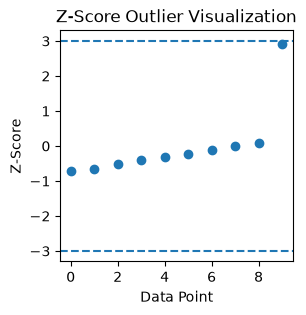

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import zscore

data = np.array([10, 12, 15, 18, 20, 22, 25, 28, 30, 100])

z_scores = zscore(data)
plt.figure(figsize=(3,3))
plt.scatter(range(len(data)),z_scores)


plt.axhline(3, linestyle="--")
plt.axhline(-3, linestyle="--")

plt.xlabel("Data Point")
plt.ylabel("Z-Score")
plt.title("Z-Score Outlier Visualization")

plt.show()

{'whiskers': [<matplotlib.lines.Line2D at 0x1a75a7eb1d0>,
 'caps': [<matplotlib.lines.Line2D at 0x1a75a7eb6b0>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a75a7e96a0>],
 'medians': [<matplotlib.lines.Line2D at 0x1a75a7ebbc0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a75a7712e0>],
 'means': []}

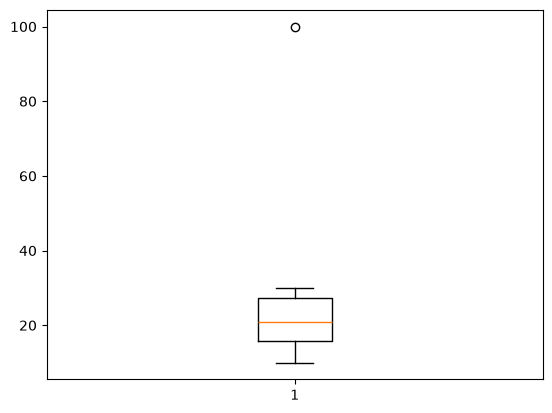

In [46]:
plt.boxplot(data)

In [47]:
import seaborn as sns
import pandas as pd 

df=sns.load_dataset('tips')

In [48]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


{'whiskers': [<matplotlib.lines.Line2D at 0x1a75a84d100>,
 'caps': [<matplotlib.lines.Line2D at 0x1a75a84d610>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a75a84ce90>],
 'medians': [<matplotlib.lines.Line2D at 0x1a75a84daf0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a75a84dd90>],
 'means': []}

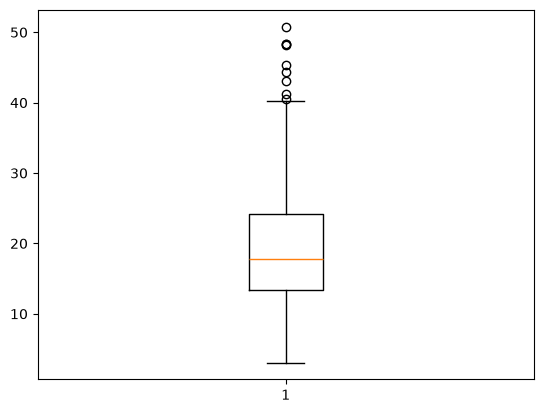

In [49]:
plt.boxplot(df['total_bill'])

In [50]:
q1=df['total_bill'].quantile(0.25)
q3=df['total_bill'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)

lower=q1-1.5*iqr

upper= q3-1.5*iqr

df=df[(df['total_bill']<upper) & (df['total_bill']>lower)]

iqr----- 10.779999999999998


In [51]:
df.shape

(7, 7)

In [52]:
q1=df['tip'].quantile(0.25)
q3=df['tip'].quantile(0.75)
iqr=q3-q1
print('iqr-----',iqr)

lower=q1-1.5*iqr
print('lower--------', lower)
upper= q3-1.5*iqr
print('upper--------', upper)

iqr----- 0.72
lower-------- -0.08000000000000007
upper-------- 0.6399999999999999


{'whiskers': [<matplotlib.lines.Line2D at 0x1a75a88bd70>,
 'caps': [<matplotlib.lines.Line2D at 0x1a75b884290>,
 'boxes': [<matplotlib.lines.Line2D at 0x1a75a88bb30>],
 'medians': [<matplotlib.lines.Line2D at 0x1a75b8847a0>],
 'fliers': [<matplotlib.lines.Line2D at 0x1a75b884a40>],
 'means': []}

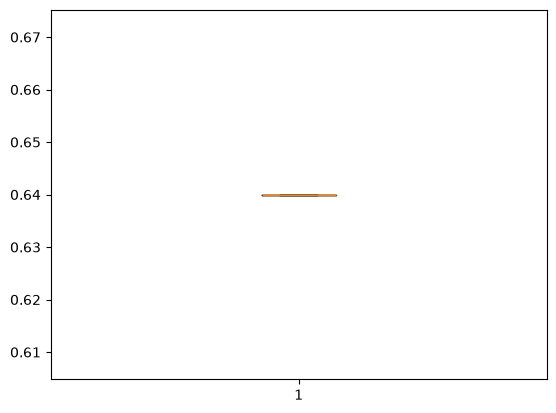

In [53]:
df['tip']=df['tip'].clip(upper=upper)
plt.boxplot(df['tip'])

In [54]:
df

,total_bill,tip,sex,smoker,day,time,size
67,3.07,0.64,Female,Yes,Sat,Dinner,1
92,5.75,0.64,Female,Yes,Fri,Dinner,2
111,7.25,0.64,Female,No,Sat,Dinner,1
149,7.51,0.64,Male,No,Thur,Lunch,2
172,7.25,0.64,Male,Yes,Sun,Dinner,2
195,7.56,0.64,Male,No,Thur,Lunch,2
218,7.74,0.64,Male,Yes,Sat,Dinner,2


In [55]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

In [56]:
df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [57]:
num_fea=['total_bill']
ohe_fea=['sex','smoker']
min_max=['tip']

In [58]:
from sklearn.preprocessing import MinMaxScaler

transform=ColumnTransformer(

transformers=[('num',StandardScaler(),num_fea),
('min_max',MinMaxScaler(),min_max),
('cat',OneHotEncoder(drop='first'),ohe_fea),
], remainder='passthrough'
)

In [59]:
transform.fit_transform(df)

array([[-2.253647015330439, 0.0, 0.0, 1.0, 'Sat', 'Dinner', 1],
       [-0.5378021286584006, 0.0, 0.0, 1.0, 'Fri', 'Dinner', 2],
       [0.4225588153744568, 0.0, 0.0, 0.0, 'Sat', 'Dinner', 1],
       [0.5890213790068185, 0.0, 1.0, 0.0, 'Thur', 'Lunch', 2],
       [0.4225588153744568, 0.0, 1.0, 1.0, 'Sun', 'Dinner', 2],
       [0.6210334104745804, 0.0, 1.0, 0.0, 'Thur', 'Lunch', 2],
       [0.7362767237585236, 0.0, 1.0, 1.0, 'Sat', 'Dinner', 2]],
      dtype=object)

In [60]:
pd.DataFrame(transform.fit_transform(df),columns=transform.get_feature_names_out())

,num__total_bill,min_max__tip,cat__sex_Male,cat__smoker_Yes,remainder__day,remainder__time,remainder__size
0,-2.253647,0.0,0.0,1.0,Sat,Dinner,1
1,-0.537802,0.0,0.0,1.0,Fri,Dinner,2
2,0.422559,0.0,0.0,0.0,Sat,Dinner,1
3,0.589021,0.0,1.0,0.0,Thur,Lunch,2
4,0.422559,0.0,1.0,1.0,Sun,Dinner,2
5,0.621033,0.0,1.0,0.0,Thur,Lunch,2
6,0.736277,0.0,1.0,1.0,Sat,Dinner,2
